# Financial NLP fine-tuning and model export

Run this notebook on Kaggle with a GPU and Internet enabled. Attach the finance benchmark dataset containing `financial_phrasebank_allagree.csv`, `twitter_financial_news_sentiment.csv`, `fiqa_2018_sentiment_regression.csv`, and `financial_news_ticker_linking.csv`.

The notebook fine-tunes the project’s Laya model and FLANG-RoBERTa models for sentiment classification and FiQA regression. It selects each FLANG-RoBERTa checkpoint using validation macro-F1 (classification) or RMSE (regression), saves tokenizer/config/weights, then creates `/kaggle/working/financial_model_export.zip`. In the Kaggle notebook editor, use **Save Version** and enable **Save output** to download the ZIP from the output panel.

> The Laya fine-tuning recipe below is reused from the project’s final Laya notebook; it trains the multitask Laya model over its sentiment and ticker training examples. The FLANG-RoBERTa classifier is trained jointly on PhraseBank and Twitter after mapping both corpora to the same negative/neutral/positive labels. Their test sets remain separate for dataset-specific evaluation.

In [1]:
%pip -q install -U "transformers<5" sentencepiece laya==0.3.24 safetensors huggingface_hub scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.6/106.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 298.9/298.9 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 104.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 104.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 88.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel

In [2]:
import ast, json, os, random, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
    mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
    hamming_loss, average_precision_score)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Enable a Kaggle GPU accelerator before running the training and inference cells.")
DEVICE = "cuda"
print("GPU:", torch.cuda.get_device_name(0), "| PyTorch:", torch.__version__)

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/financial_model_export")
MODEL_DIR = OUTPUT_DIR / "FLANG_Laya"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR = OUTPUT_DIR

# Start modestly; set a limit to None for the full corresponding split.
CLASSIFICATION_TRAIN_LIMIT = None
REGRESSION_TRAIN_LIMIT = 800
TICKER_TRAIN_ARTICLE_LIMIT = 50
CLASSIFICATION_TEST_LIMIT = 300
REGRESSION_TEST_LIMIT = 300
TICKER_VALIDATION_LIMIT = 50
TICKER_TEST_LIMIT = 100
INFERENCE_BATCH_SIZE = 8

RUN_FINETUNING = True
USE_EXISTING_FINETUNED_MODEL = False
EPOCHS = 12
MICRO_BATCH_SIZE = 2
GRADIENT_ACCUMULATION = 8
RLCD_GROUP_SIZE = 4
LR_ENCODER = 2.0e-5
LR_HEAD = 8.0e-5


GPU: Tesla T4 | PyTorch: 2.11.0+cu128


In [3]:
def find_csv(filename):
    matches = list(INPUT_ROOT.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Attach the benchmark dataset containing {filename} to this Kaggle notebook.")
    return matches[0]

PATHS = {
    "phrasebank": find_csv("financial_phrasebank_allagree.csv"),
    "twitter": find_csv("twitter_financial_news_sentiment.csv"),
    "fiqa": find_csv("fiqa_2018_sentiment_regression.csv"),
    "ticker": find_csv("financial_news_ticker_linking.csv"),
}
for name, path in PATHS.items(): print(f"{name}: {path}")


phrasebank: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/financial_phrasebank_dataset/financial_phrasebank_allagree.csv
twitter: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/twitter_financial_news_sentiment.csv
fiqa: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/fiqa_2018_sentiment_regression.csv
ticker: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/financial_news_ticker_linking.csv


In [4]:
LABELS = ["negative", "neutral", "positive"]
CLASS_CRITERIA = {
    "negative": "Financially negative or bearish outlook for the company, asset, or market.",
    "neutral": "Factual, mixed, or no clear positive or negative financial sentiment.",
    "positive": "Financially positive or bullish outlook for the company, asset, or market."
}
SCORE_VALUES = np.linspace(-1.0, 1.0, 11)
SCORE_CRITERIA = [f"Overall financial sentiment {v:+.1f} (-1 very negative, +1 very positive)." for v in SCORE_VALUES]
TICKERS = ["AAPL","MSFT","GOOGL","AMZN","NVDA","META","TSLA","BRK.B","JPM","V","JNJ","WMT","PG","MA","HD","XOM","CVX","LLY","ABBV","MRK","BAC","KO","PEP","COST","AVGO","ORCL","ADBE","CRM","NFLX","AMD","INTC","CSCO","QCOM","TXN","IBM","DIS","NKE","MCD","T","PFE","UNH","CAT","GE","BA","GS","C","WFC","PYPL","UBER"]

def norm_label(x):
    x=str(x).strip().lower()
    return {"bearish":"negative", "bullish":"positive", "neg":"negative", "neu":"neutral", "pos":"positive"}.get(x,x)

def split_train_validation(frame, label_col=None, test_size=.1):
    if label_col and frame[label_col].nunique()>1:
        train, val = train_test_split(frame, test_size=test_size, random_state=SEED, stratify=frame[label_col])
    else:
        train, val = train_test_split(frame, test_size=test_size, random_state=SEED)
    return train.reset_index(drop=True), val.reset_index(drop=True)

def apply_limit(frame, limit):
    if limit is None or len(frame)<=limit: return frame.reset_index(drop=True)
    return frame.sample(n=limit, random_state=SEED).reset_index(drop=True)

def classification_split(dataset):
    df=pd.read_csv(PATHS[dataset]).dropna(subset=["text","label"]).copy()
    df["text"]=df.text.astype(str); df["label"]=df.label.map(norm_label)
    df=df[df.label.isin(LABELS)].drop_duplicates("text").reset_index(drop=True)
    if dataset=="twitter" and "split" in df and df.split.astype(str).str.lower().eq("test").any():
        test=df[df.split.astype(str).str.lower().eq("test")].copy()
        trainval=df[~df.split.astype(str).str.lower().eq("test")].copy()
        train,val=split_train_validation(trainval,"label")
    else:
        trainval,test=train_test_split(df,test_size=.1,random_state=SEED,stratify=df.label)
        train,val=split_train_validation(trainval,"label",test_size=1/9)
    return train.reset_index(drop=True),val.reset_index(drop=True),test.reset_index(drop=True)

CLASS_DATA={name:classification_split(name) for name in ["phrasebank","twitter"]}
for name,(tr,va,te) in CLASS_DATA.items(): print(name, "train/val/test:",len(tr),len(va),len(te),"train labels:",tr.label.value_counts().to_dict())

fiqa=pd.read_csv(PATHS["fiqa"]).dropna(subset=["sentence","sentiment_score"]).copy()
fiqa["sentiment_score"]=pd.to_numeric(fiqa.sentiment_score,errors="coerce")
fiqa=fiqa.dropna(subset=["sentiment_score"]); fiqa.sentiment_score=fiqa.sentiment_score.clip(-1,1)
if "split" in fiqa and fiqa.split.astype(str).str.lower().eq("test").any():
    fiqa_test=fiqa[fiqa.split.astype(str).str.lower().eq("test")].copy()
    fiqa_trainval=fiqa[~fiqa.split.astype(str).str.lower().eq("test")].copy()
    fiqa_train,fiqa_val=split_train_validation(fiqa_trainval)
else:
    fiqa_trainval,fiqa_test=train_test_split(fiqa,test_size=.2,random_state=SEED)
    fiqa_train,fiqa_val=split_train_validation(fiqa_trainval)
fiqa_train,fiqa_val,fiqa_test=[x.reset_index(drop=True) for x in [fiqa_train,fiqa_val,fiqa_test]]
print("FiQA train/val/test:",len(fiqa_train),len(fiqa_val),len(fiqa_test))

def parse_tickers(value):
    try: value=json.loads(value) if isinstance(value,str) else value
    except Exception:
        try: value=ast.literal_eval(value)
        except Exception: value=[]
    if not isinstance(value,(list,tuple,set)): value=[value] if value else []
    return sorted({str(x).strip().upper().replace("$","") for x in value if str(x).strip()})

ticker=pd.read_csv(PATHS["ticker"],usecols=["text","title","date_publish","url","mentioned_companies"],low_memory=False)
ticker=ticker.dropna(subset=["mentioned_companies"])
ticker["text"]=ticker.text.fillna("").astype(str); ticker["title"]=ticker.title.fillna("").astype(str)
ticker["url"]=ticker.url.fillna("").astype(str)
ticker["_norm"]=ticker.text.str.lower().str.replace(r"\s+"," ",regex=True).str.strip()
ticker=ticker[ticker._norm.ne("")]
if ticker.url.ne("").any(): ticker=ticker.drop_duplicates("url")
ticker=ticker.drop_duplicates("_norm").reset_index(drop=True)
ticker["gold_tickers"]=ticker.mentioned_companies.map(parse_tickers)
ticker["_date"]=pd.to_datetime(ticker.date_publish,errors="coerce",utc=True)
ticker=ticker.sort_values("_date",na_position="first").reset_index(drop=True)
has_label=ticker.gold_tickers.map(lambda xs: bool(set(xs)&set(TICKERS)))
ticker=ticker[has_label].reset_index(drop=True)
split_a=int(len(ticker)*.70); split_b=int(len(ticker)*.85)
ticker_train=ticker.iloc[:split_a].copy(); ticker_val=ticker.iloc[split_a:split_b].copy(); ticker_test=ticker.iloc[split_b:].copy()
ticker_train=apply_limit(ticker_train,TICKER_TRAIN_ARTICLE_LIMIT)
ticker_val=apply_limit(ticker_val,TICKER_VALIDATION_LIMIT)
ticker_test=apply_limit(ticker_test,TICKER_TEST_LIMIT)
print("Ticker articles train/val/test:",len(ticker_train),len(ticker_val),len(ticker_test))


phrasebank train/val/test: 1807 226 226 train labels: {'neutral': 1108, 'positive': 456, 'negative': 243}
twitter train/val/test: 9544 1193 1194 train labels: {'neutral': 6195, 'positive': 1918, 'negative': 1431}
FiQA train/val/test: 956 107 150
Ticker articles train/val/test: 50 50 100


In [5]:
def state_for_class(row): return str(row.text)[:2500]
def class_question(): return {"type":"choice","instructions":"Classify the overall sentiment toward the financial company, security, or market described in the text.","criteria":CLASS_CRITERIA}
def state_for_fiqa(row):
    target=str(row.get("target", "")).strip()
    return f"Target: {target}\nText: {str(row.sentence)[:2500]}"
def regression_question(): return {"type":"score","instructions":"Rate the overall financial sentiment toward the stated target. Negative values mean bearish/negative, zero means neutral or mixed, and positive values mean bullish/positive.","criteria":SCORE_CRITERIA}
def state_for_ticker(row): return (str(row.title)+"\n\n"+str(row.text))[:2500]
def ticker_question(symbol):
    return {"type":"noul","instructions":f"Does this article explicitly discuss {symbol} as a relevant company or security? Ignore unrelated incidental mentions.","criteria":{"true":f"The article explicitly discusses {symbol}.","false":f"The article does not discuss {symbol}."}}

def one_hot(n,idx):
    x=np.zeros(n,dtype=np.float32); x[idx]=1.; return x.tolist()

def score_distribution(value):
    pos=float(np.clip((float(value)+1.0)/2.0*(len(SCORE_VALUES)-1),0,len(SCORE_VALUES)-1))
    lo=int(np.floor(pos)); hi=min(lo+1,len(SCORE_VALUES)-1); frac=pos-lo
    out=np.zeros(len(SCORE_VALUES),dtype=np.float32); out[lo]+=1-frac; out[hi]+=frac
    return out.tolist()

train_records=[]; calibration_records=[]
for dataset,(train_df,val_df,_) in CLASS_DATA.items():
    train_df=apply_limit(train_df,CLASSIFICATION_TRAIN_LIMIT)
    for _,r in train_df.iterrows():
        train_records.append({"state":state_for_class(r),"question":class_question(),"target":one_hot(3,LABELS.index(r.label)),"task":"classification"})
    for _,r in val_df.iterrows():
        calibration_records.append({"state":state_for_class(r),"question":class_question(),"target":one_hot(3,LABELS.index(r.label)),"task":"classification"})

fiqa_train_sample=apply_limit(fiqa_train,REGRESSION_TRAIN_LIMIT)
for _,r in fiqa_train_sample.iterrows():
    train_records.append({"state":state_for_fiqa(r),"question":regression_question(),"target":score_distribution(r.sentiment_score),"task":"regression"})
for _,r in fiqa_val.iterrows():
    calibration_records.append({"state":state_for_fiqa(r),"question":regression_question(),"target":score_distribution(r.sentiment_score),"task":"regression"})

for _,r in ticker_train.iterrows():
    positives=sorted(set(r.gold_tickers)&set(TICKERS))
    negatives=[s for s in TICKERS if s not in positives]
    if not positives: continue
    rng=random.Random(SEED+int(r.name))
    sampled_negatives=rng.sample(negatives,min(len(negatives),5*len(positives)))
    state=state_for_ticker(r)
    for symbol in positives+sampled_negatives:
        is_positive=int(symbol in positives)
        train_records.append({"state":state,"question":ticker_question(symbol),"target":one_hot(2,1 if is_positive else 0),"task":"ticker"})
for _,r in ticker_val.iterrows():
    state=state_for_ticker(r)
    for symbol in TICKERS:
        is_positive=int(symbol in set(r.gold_tickers))
        calibration_records.append({"state":state,"question":ticker_question(symbol),"target":one_hot(2,1 if is_positive else 0),"task":"ticker"})

print("Training decisions:",len(train_records),pd.Series([x["task"] for x in train_records]).value_counts().to_dict())
print("Calibration decisions:",len(calibration_records))
if RUN_FINETUNING and len(train_records)<100:
    raise ValueError("Too few training decisions were built. Check the input CSVs and label mappings.")


Training decisions: 12571 {'classification': 11351, 'regression': 800, 'ticker': 420}
Calibration decisions: 3976


In [6]:
import laya
from huggingface_hub import snapshot_download
from safetensors.torch import load_file, save_file
from transformers import AutoTokenizer
from laya.agent import _fix_tokenizer_config
from laya.common import build_sequence, render_options, QTYPES, build_model, proper_reward, TEMP_MIN, TEMP_MAX

BASE_MODEL_ID="convaiinnovations/laya"
BASE_MODEL_DIR=snapshot_download(BASE_MODEL_ID)
_fix_tokenizer_config(BASE_MODEL_DIR)
with open(Path(BASE_MODEL_DIR)/"rl_agent_config.json",encoding="utf-8") as f: BASE_CONFIG=json.load(f)
TOKENIZER=AutoTokenizer.from_pretrained(Path(BASE_MODEL_DIR)/"tokenizer")
BASE_CONFIG["max_len"]=512
BASE_CONFIG["head_max_len"]=192
BASE_CONFIG["gradient_checkpointing"]=True

def make_item(record):
    q=record["question"]
    qtype={"t":q["type"],"ins":q["instructions"],"crit":q.get("criteria",{})}
    seq,markers=build_sequence(TOKENIZER,record["state"],qtype,BASE_CONFIG["max_len"],BASE_CONFIG["head_max_len"])
    expected=len(render_options(qtype))
    if len(markers)!=expected: return None
    target=record["target"]
    if len(target)!=expected: raise ValueError(f"Target has {len(target)} levels but question renders {expected} options")
    return {"ids":seq,"markers":markers,"qtype":QTYPES[q["type"]],"target":target,"label":int(np.argmax(target))}

if RUN_FINETUNING:
    train_items=[x for rec in tqdm(train_records,desc="Tokenize train decisions") if (x:=make_item(rec)) is not None]
    calibration_items=[x for rec in tqdm(calibration_records,desc="Tokenize calibration decisions") if (x:=make_item(rec)) is not None]
    print("Tokenized train/calibration:",len(train_items),len(calibration_items))


Fetching 39 files:   0%|          | 0/39 [00:00<?, ?it/s]

.gitattributes: 0.00B [00:00, ?B/s]

logo-lockup-dark.png:   0%|          | 0.00/27.7k [00:00<?, ?B/s]

logo-lockup-dark.svg: 0.00B [00:00, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

typed-decisions/model.safetensors:   0%|          | 0.00/843M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/337 [00:00<?, ?B/s]

Tokenize train decisions:   0%|          | 0/12571 [00:00<?, ?it/s]

Tokenize calibration decisions:   0%|          | 0/3976 [00:00<?, ?it/s]

Tokenized train/calibration: 12571 3976


In [7]:
def collate_items(items,pad_id):
    n=len(items); length=max(len(x["ids"]) for x in items); kmax=max(len(x["markers"]) for x in items)
    ids=torch.full((n,length),pad_id,dtype=torch.long); att=torch.zeros((n,length),dtype=torch.long)
    mpos=torch.zeros((n,kmax),dtype=torch.long); mmask=torch.zeros((n,kmax),dtype=torch.bool)
    target=torch.zeros((n,kmax),dtype=torch.float32)
    for i,it in enumerate(items):
        ids[i,:len(it["ids"])]=torch.tensor(it["ids"]); att[i,:len(it["ids"])]=1
        k=len(it["markers"]); mpos[i,:k]=torch.tensor(it["markers"]); mmask[i,:k]=True
        target[i,:len(it["target"])]=torch.tensor(it["target"],dtype=torch.float32)
    return ids,att,mpos,mmask,target,torch.tensor([x["qtype"] for x in items])

def fit_temperature(rows):
    if len(rows)<10: return 1.0
    kmax=max(len(z) for z,t in rows); z=torch.full((len(rows),kmax),-1e4); target=torch.zeros((len(rows),kmax))
    for i,(logits,dist) in enumerate(rows):
        z[i,:len(logits)]=torch.as_tensor(logits); target[i,:len(dist)]=torch.as_tensor(dist)
    log_t=torch.zeros(1,requires_grad=True); opt=torch.optim.LBFGS([log_t],lr=.1,max_iter=80)
    def closure():
        opt.zero_grad(); loss=-(target*torch.log_softmax(z/log_t.exp(),dim=-1)).sum(-1).mean(); loss.backward(); return loss
    opt.step(closure)
    return float(torch.clamp(log_t.exp(),TEMP_MIN,TEMP_MAX).item())

if RUN_FINETUNING:
    cfg=dict(BASE_CONFIG)
    model=build_model(cfg,encoder_dir=str(Path(BASE_MODEL_DIR)/"encoder"))
    model.load_state_dict(load_file(str(Path(BASE_MODEL_DIR)/"model.safetensors")),strict=True)
    if hasattr(model.encoder,"gradient_checkpointing_enable"):
        model.encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant":False})
    model.head_checkpointing=True
    model.to(DEVICE).train()
    enc_params=[p for n,p in model.named_parameters() if "encoder." in n]
    head_params=[p for n,p in model.named_parameters() if "encoder." not in n]
    optimizer=torch.optim.AdamW([{"params":enc_params,"lr":LR_ENCODER},{"params":head_params,"lr":LR_HEAD}],weight_decay=.01)
    steps=max(1,(len(train_items)//MICRO_BATCH_SIZE//GRADIENT_ACCUMULATION)*EPOCHS)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=steps,eta_min=1e-6)
    scaler=torch.amp.GradScaler("cuda",enabled=True)
    pad_id=TOKENIZER.pad_token_id or 0

    for epoch in range(EPOCHS):
        random.shuffle(train_items); losses=[]; optimizer.zero_grad(set_to_none=True)
        sigma=.30+(.08-.30)*(epoch/max(1,EPOCHS-1))
        for start in tqdm(range(0,len(train_items),MICRO_BATCH_SIZE),desc=f"RLCD epoch {epoch+1}/{EPOCHS}"):
            batch=collate_items(train_items[start:start+MICRO_BATCH_SIZE],pad_id)
            ids,att,mpos,mmask,target,qtype=[x.to(DEVICE) for x in batch]
            with torch.autocast("cuda",dtype=torch.float16):
                logits,act=model(ids,att,mpos,mmask,qtype)
            logits=logits.float(); mask=mmask; k=mask.sum(-1,keepdim=True).float()
            eps=torch.randn((RLCD_GROUP_SIZE,)+logits.shape,device=DEVICE)*sigma*mask
            eps=(eps-eps.sum(-1,keepdim=True)/k)*mask
            z=logits.detach().unsqueeze(0)+eps
            q=torch.softmax(z.masked_fill(~mask,-1e4),dim=-1)
            with torch.no_grad():
                reward=proper_reward(q,target.unsqueeze(0),qtype,mask,w_sph=.75,w_rps=1.0)
                advantage=reward-reward.mean(0,keepdim=True)
                advantage=advantage/(advantage.std()+1e-6)
            logp=-(((z-logits.unsqueeze(0))**2)*mask).sum(-1)/(2*sigma**2)
            loss_rl=-(advantage*logp).mean()
            loss_ce=-(target*torch.log_softmax(logits.masked_fill(~mask,-1e4),dim=-1)).sum(-1).mean()
            loss=(loss_rl+loss_ce)/GRADIENT_ACCUMULATION+0.0*act.sum()
            scaler.scale(loss).backward(); losses.append(float(loss.detach().cpu()))
            at_end=(start+MICRO_BATCH_SIZE>=len(train_items))
            if ((start//MICRO_BATCH_SIZE+1)%GRADIENT_ACCUMULATION==0) or at_end:
                scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
        print(f"Epoch {epoch+1}: mean loss={np.mean(losses):.4f}")
        MODEL_DIR.mkdir(parents=True,exist_ok=True)
        save_file({k:v.half().contiguous().cpu() for k,v in model.state_dict().items()},str(MODEL_DIR/"model.safetensors"))
        model.encoder.config.save_pretrained(MODEL_DIR/"encoder"); TOKENIZER.save_pretrained(MODEL_DIR/"tokenizer")

    # Fit one temperature for each typed question family on validation/calibration only.
    model.eval(); temp_rows={0:[],1:[],2:[]}
    with torch.no_grad():
        for start in tqdm(range(0,len(calibration_items),8),desc="Calibrate validation decisions"):
            chunk=calibration_items[start:start+8]
            ids,att,mpos,mmask,target,qtype=[x.to(DEVICE) for x in collate_items(chunk,pad_id)]
            with torch.autocast("cuda",dtype=torch.float16): logits,_=model(ids,att,mpos,mmask,qtype)
            logits=logits.float().cpu().numpy()
            for i,item in enumerate(chunk):
                temp_rows[item["qtype"]].append((logits[i,:len(item["target"])],item["target"]))
    temperature=[fit_temperature(temp_rows.get(i,[])) for i in range(3)]
    cfg["fine_tuned"]=True; cfg["model_name"]="laya-financial-benchmark"; cfg["temperature"]=temperature
    cfg.pop("temperature_by_options",None)
    with open(MODEL_DIR/"rl_agent_config.json","w",encoding="utf-8") as f: json.dump(cfg,f,indent=2)
    del model; torch.cuda.empty_cache()
    print("Fine-tuned model saved:",MODEL_DIR,"| temperatures:",temperature)


RLCD epoch 1/12:   0%|          | 0/6286 [00:00<?, ?it/s]

W1004 13:15:59.279000 23 torch/_inductor/utils.py:1731] [1/0_1] Not enough SMs to use max_autotune_gemm mode
/tmp/ipykernel_23/1618108693.py:64: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()


Epoch 1: mean loss=0.2116


RLCD epoch 2/12:   0%|          | 0/6286 [00:00<?, ?it/s]

Epoch 2: mean loss=0.1399


...

Epoch 11: mean loss=0.0230


RLCD epoch 12/12:   0%|          | 0/6286 [00:00<?, ?it/s]

Epoch 12: mean loss=0.0218


Calibrate validation decisions:   0%|          | 0/497 [00:00<?, ?it/s]

Fine-tuned model saved: /kaggle/working/financial_model_export/FLANG_Laya | temperatures: [5.0, 2.0819668769836426, 5.0]


## FLANG-RoBERTa fine-tuning

This section trains a fresh model for each classification corpus and one FiQA regressor. The best validation checkpoint is restored before exporting. The held-out test split is not used for checkpoint selection.

In [8]:
import copy, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, mean_squared_error, mean_absolute_error, r2_score

FLANG_ID = "SALT-NLP/FLANG-Roberta"
FLANG_DIR = OUTPUT_DIR / "flang_roberta"
FLANG_DIR.mkdir(parents=True, exist_ok=True)
FLANG_MAX_LENGTH = 128
FLANG_BATCH = 16
FLANG_EPOCHS = 8
FLANG_PATIENCE = 2
FLANG_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABELS_EXPORT = ["negative", "neutral", "positive"]
LABEL_TO_ID_EXPORT = {x:i for i,x in enumerate(LABELS_EXPORT)}

def seeded(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

class EncoderHead(nn.Module):
    def __init__(self, checkpoint, output_size, dropout=0.2):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(checkpoint)
        cfg=self.encoder.config
        dim=getattr(cfg,"hidden_size",None) or getattr(cfg,"dim",None) or getattr(cfg,"d_model",None)
        self.head=nn.Sequential(nn.Linear(dim,256),nn.LayerNorm(256),nn.GELU(),nn.Dropout(dropout),nn.Linear(256,output_size))
    def forward(self,input_ids,attention_mask,token_type_ids=None):
        args={"input_ids":input_ids,"attention_mask":attention_mask}
        if token_type_ids is not None: args["token_type_ids"]=token_type_ids
        out=self.encoder(**args)
        pooled=getattr(out,"pooler_output",None)
        if pooled is None: pooled=out.last_hidden_state[:,0]
        return self.head(pooled)

class FrameDataset(Dataset):
    def __init__(self, frame, tokenizer, text_col, target_col, max_length=FLANG_MAX_LENGTH):
        self.texts=frame[text_col].astype(str).tolist(); self.targets=frame[target_col].tolist()
        self.tokenizer=tokenizer; self.max_length=max_length
    def __len__(self): return len(self.targets)
    def __getitem__(self,i):
        x=self.tokenizer(self.texts[i],truncation=True,max_length=self.max_length,padding=False)
        x["labels"]=self.targets[i]; return x

def batch_collator(tokenizer, regression=False):
    def collate(rows):
        labels=[r.pop("labels") for r in rows]
        x=tokenizer.pad(rows,padding=True,return_tensors="pt")
        x["labels"]=torch.tensor(labels,dtype=torch.float32 if regression else torch.long)
        return x
    return collate

def move_inputs(batch):
    return {k:v.to(FLANG_DEVICE) for k,v in batch.items() if k!="labels"}

def evaluate_task(model, loader, task):
    model.eval(); ys=[]; ps=[]
    with torch.inference_mode():
        for b in loader:
            y=b["labels"].cpu().numpy(); pred=model(**move_inputs(b))
            if task=="classification": pred=pred.argmax(-1).cpu().numpy()
            else: pred=pred.float().cpu().numpy()
            ys.extend(y.tolist()); ps.extend(pred.tolist())
    if task=="classification": return {"macro_f1":float(f1_score(ys,ps,average="macro",zero_division=0))}
    return {"rmse":float(mean_squared_error(ys,ps)**0.5),"mae":float(mean_absolute_error(ys,ps)),"r2":float(r2_score(ys,ps))}

def train_and_export(frame_train, frame_val, *, task, text_col, target_col, artifact_name):
    seeded()
    tokenizer=AutoTokenizer.from_pretrained(FLANG_ID,use_fast=True)
    regression=(task=="regression")
    train_loader=DataLoader(FrameDataset(frame_train,tokenizer,text_col,target_col),batch_size=FLANG_BATCH,shuffle=True,collate_fn=batch_collator(tokenizer,regression))
    val_loader=DataLoader(FrameDataset(frame_val,tokenizer,text_col,target_col),batch_size=FLANG_BATCH,shuffle=False,collate_fn=batch_collator(tokenizer,regression))
    n_outputs=1 if regression else len(LABELS_EXPORT)
    model=EncoderHead(FLANG_ID,n_outputs).to(FLANG_DEVICE)
    head_ids={id(p) for p in model.head.parameters()}
    enc=[p for p in model.parameters() if id(p) not in head_ids]
    optimizer=torch.optim.AdamW([{"params":enc,"lr":5e-6},{"params":model.head.parameters(),"lr":2.5e-5}],weight_decay=.01)
    total=max(1,len(train_loader)*FLANG_EPOCHS)
    scheduler=get_linear_schedule_with_warmup(optimizer,int(.1*total),total)
    loss_fn=nn.SmoothL1Loss(beta=.1) if regression else nn.CrossEntropyLoss()
    best_score=float("inf") if regression else -1.; best_state=None; stale=0
    for epoch in range(1,FLANG_EPOCHS+1):
        model.train()
        for batch in train_loader:
            y=batch["labels"].to(FLANG_DEVICE); optimizer.zero_grad(set_to_none=True)
            pred=model(**move_inputs(batch)); loss=loss_fn(pred.squeeze(-1) if regression else pred,y)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.); optimizer.step(); scheduler.step()
        score=evaluate_task(model,val_loader,task)
        primary=score["rmse"] if regression else score["macro_f1"]
        better=primary<best_score if regression else primary>best_score
        print(f"{artifact_name} epoch {epoch}: val={score}")
        if better:
            best_score=primary; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; stale=0
        else:
            stale+=1
            if stale>=FLANG_PATIENCE: break
    model.load_state_dict(best_state)
    out=FLANG_DIR/artifact_name; out.mkdir(parents=True,exist_ok=True)
    model.encoder.save_pretrained(out/"encoder",safe_serialization=True)
    tokenizer.save_pretrained(out/"tokenizer")
    torch.save({k:v.cpu() for k,v in model.head.state_dict().items()},out/"head.pt")
    cfg={"backend":"encoder_plus_head","task":task,"model_id":FLANG_ID,"labels":LABELS_EXPORT if not regression else None,"max_length":FLANG_MAX_LENGTH,"head_hidden_size":256,"dropout":0.2,"selection_metric":"validation_rmse" if regression else "validation_macro_f1","best_validation_score":best_score}
    (out/"model_config.json").write_text(json.dumps(cfg,indent=2),encoding="utf-8")
    return model,tokenizer,out


### Prepare both classification datasets and train one joint model

In [9]:
# PhraseBank: stratified train/validation/test split (test retained only for later evaluation).
phrase_path=find_csv("financial_phrasebank_allagree.csv")
phrase=pd.read_csv(phrase_path).dropna(subset=["text","label"]).copy()
phrase["label"]=phrase.label.astype(str).str.lower().map(LABEL_TO_ID_EXPORT)
phrase=phrase.dropna(subset=["label"]); phrase["label"]=phrase.label.astype(int)
phrase_train,phrase_rest=train_test_split(phrase,test_size=.2,random_state=SEED,stratify=phrase.label)
phrase_val,phrase_test=train_test_split(phrase_rest,test_size=.5,random_state=SEED,stratify=phrase_rest.label)

# Twitter dataset mirrors the final benchmark: source train is split into train/validation;
# the supplied validation partition is kept as test, with no leakage into selection.
twitter_path=find_csv("twitter_financial_news_sentiment.csv")
twitter=pd.read_csv(twitter_path).dropna(subset=["text","label","split"]).copy()
map_twitter={"bearish":"negative","neutral":"neutral","bullish":"positive"}
twitter["label"]=twitter.label.astype(str).str.lower().map(map_twitter).map(LABEL_TO_ID_EXPORT)
twitter=twitter.dropna(subset=["label"]); twitter["label"]=twitter.label.astype(int)
source_train=twitter[twitter.split.astype(str).str.lower()=="train"].copy()
twitter_test=twitter[twitter.split.astype(str).str.lower()=="validation"].copy()
twitter_train,twitter_val=train_test_split(source_train,test_size=.1,random_state=SEED,stratify=source_train.label)

# Combine the two training corpora after label normalization. The test partitions stay
# separate and are not used for model selection or gradient updates.
classification_train = pd.concat([phrase_train[["text", "label"]], twitter_train[["text", "label"]]], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
classification_val = pd.concat([phrase_val[["text", "label"]], twitter_val[["text", "label"]]], ignore_index=True).reset_index(drop=True)
classification_model,classification_tok,classification_out=train_and_export(
    classification_train,classification_val,task="classification",text_col="text",target_col="label",
    artifact_name="FLANG_RoBERTa_Sentiment_Classification")
torch.cuda.empty_cache()
print("Joint classifier training rows:",len(classification_train),"| validation rows:",len(classification_val))

# FiQA uses its supplied train/validation/test split.
fiqa_path=find_csv("fiqa_2018_sentiment_regression.csv")
fiqa=pd.read_csv(fiqa_path).dropna(subset=["sentence","sentiment_score","split"]).copy()
fiqa["sentiment_score"]=pd.to_numeric(fiqa.sentiment_score,errors="coerce"); fiqa=fiqa.dropna(subset=["sentiment_score"])
fiqa["split"]=fiqa.split.astype(str).str.lower()
fiqa_train=fiqa[fiqa.split=="train"].copy(); fiqa_val=fiqa[fiqa.split=="validation"].copy(); fiqa_test=fiqa[fiqa.split=="test"].copy()
reg_model,reg_tok,reg_out=train_and_export(fiqa_train,fiqa_val,task="regression",text_col="sentence",target_col="sentiment_score",artifact_name="FLANG_RoBERTa_Sentiment_Scorer")
torch.cuda.empty_cache()
print("FLANG-RoBERTa model folders:",classification_out,reg_out)


tokenizer_config.json:   0%|          | 0.00/311 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/761 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/540M [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at SALT-NLP/FLANG-Roberta and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/540M [00:00<?, ?B/s]

FLANG_RoBERTa_Sentiment_Classification epoch 1: val={'macro_f1': 0.8089855638295336}
FLANG_RoBERTa_Sentiment_Classification epoch 2: val={'macro_f1': 0.842032957645897}
FLANG_RoBERTa_Sentiment_Classification epoch 3: val={'macro_f1': 0.8600397700315142}
FLANG_RoBERTa_Sentiment_Classification epoch 4: val={'macro_f1': 0.8591834605378179}
FLANG_RoBERTa_Sentiment_Classification epoch 5: val={'macro_f1': 0.854685010191254}
Joint classifier training rows: 10399 | validation rows: 1181


Some weights of RobertaModel were not initialized from the model checkpoint at SALT-NLP/FLANG-Roberta and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


FLANG_RoBERTa_Sentiment_Scorer epoch 1: val={'rmse': 0.30104223105095285, 'mae': 0.2433130622604022, 'r2': 0.1914012879827286}
FLANG_RoBERTa_Sentiment_Scorer epoch 2: val={'rmse': 0.4072351043099453, 'mae': 0.32989300349179435, 'r2': -0.4796827573095199}
FLANG_RoBERTa_Sentiment_Scorer epoch 3: val={'rmse': 0.22328579281817884, 'mae': 0.17156167841498174, 'r2': 0.5551635370186491}
FLANG_RoBERTa_Sentiment_Scorer epoch 4: val={'rmse': 0.18997647880948465, 'mae': 0.15030380878962724, 'r2': 0.6779836930187959}
FLANG_RoBERTa_Sentiment_Scorer epoch 5: val={'rmse': 0.1780121661100504, 'mae': 0.14482301165002817, 'r2': 0.717266306195058}
FLANG_RoBERTa_Sentiment_Scorer epoch 6: val={'rmse': 0.1640471980390327, 'mae': 0.1315914293130239, 'r2': 0.759886912992889}
FLANG_RoBERTa_Sentiment_Scorer epoch 7: val={'rmse': 0.1594255610037487, 'mae': 0.12797178090641312, 'r2': 0.7732255589375419}
FLANG_RoBERTa_Sentiment_Scorer epoch 8: val={'rmse': 0.15425542534750558, 'mae': 0.12313540667003277, 'r2': 0.7

## Held-out evaluation tables and plots

The FLANG-RoBERTa model is scored separately on the untouched PhraseBank all-agreements and Twitter test partitions. The fine-tuned Laya model is scored on those same examples and the FiQA test split. Tables are printed and also saved as CSV; plots are saved as PNG files in the export folder.

HELD-OUT CLASSIFICATION METRICS


,task,dataset,model,n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mae,rmse,r2
2,classification,PhraseBank all-agreements,FLANG-Laya,227,1.0000,1.0000,1.0000,1.0000,1.0000,NaN,NaN,NaN
0,classification,PhraseBank all-agreements,FLANG-RoBERTa Sentiment Classification,227,0.9956,0.9976,0.9942,0.9959,0.9956,NaN,NaN,NaN
3,classification,Twitter Financial News,FLANG-Laya,2388,0.9719,0.9641,0.9638,0.9639,0.9719,NaN,NaN,NaN
1,classification,Twitter Financial News,FLANG-RoBERTa Sentiment Classification,2388,0.8953,0.8574,0.8764,0.8664,0.8960,NaN,NaN,NaN


HELD-OUT FiQA REGRESSION METRICS


,task,dataset,model,n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mae,rmse,r2
5,regression,FiQA,FLANG-Laya,150,NaN,NaN,NaN,NaN,NaN,0.1735,0.2417,0.4941
4,regression,FiQA,FLANG-RoBERTa Sentiment Scorer,150,NaN,NaN,NaN,NaN,NaN,0.2087,0.2884,0.2797


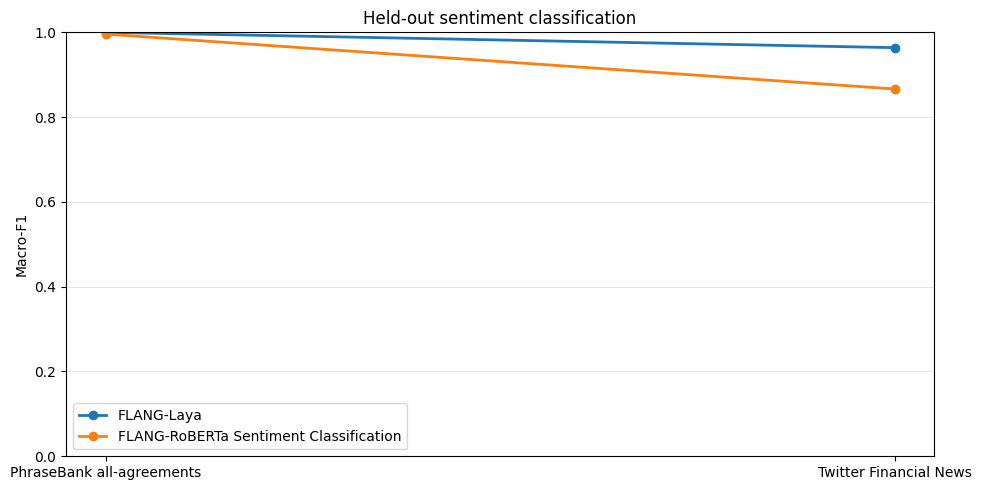

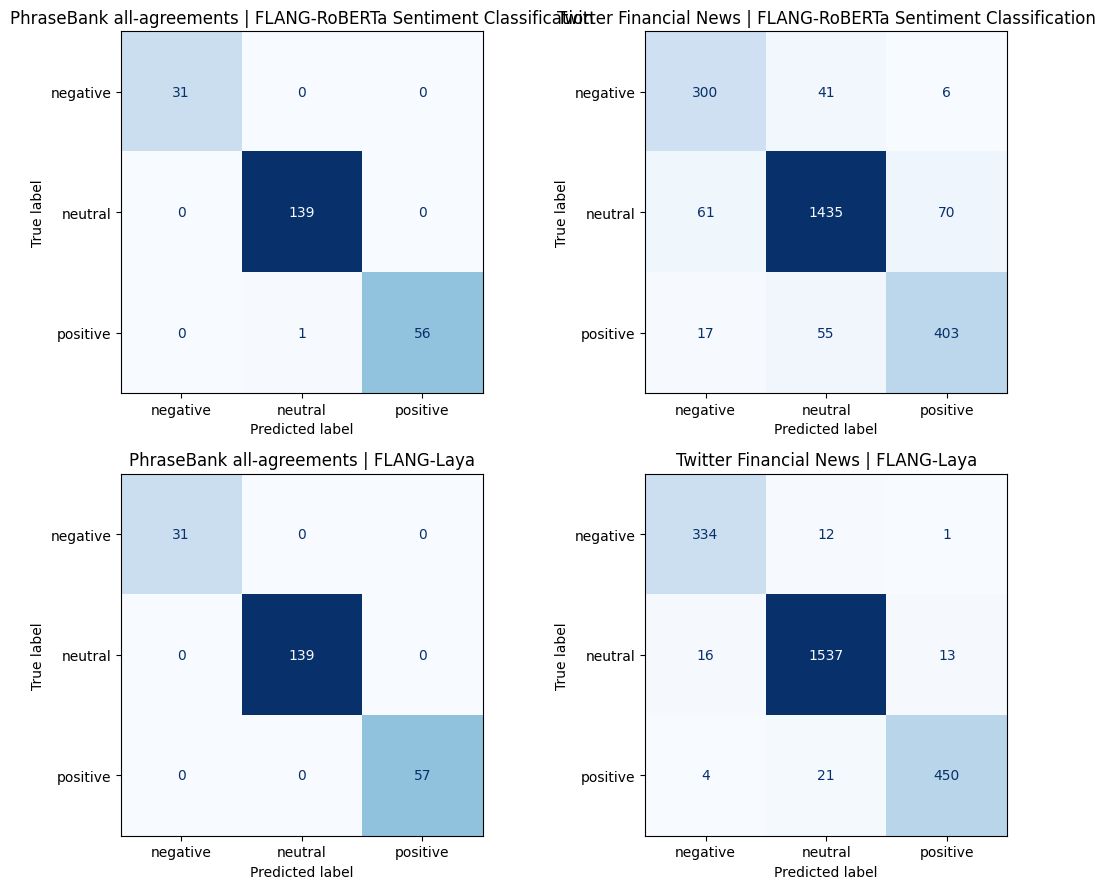

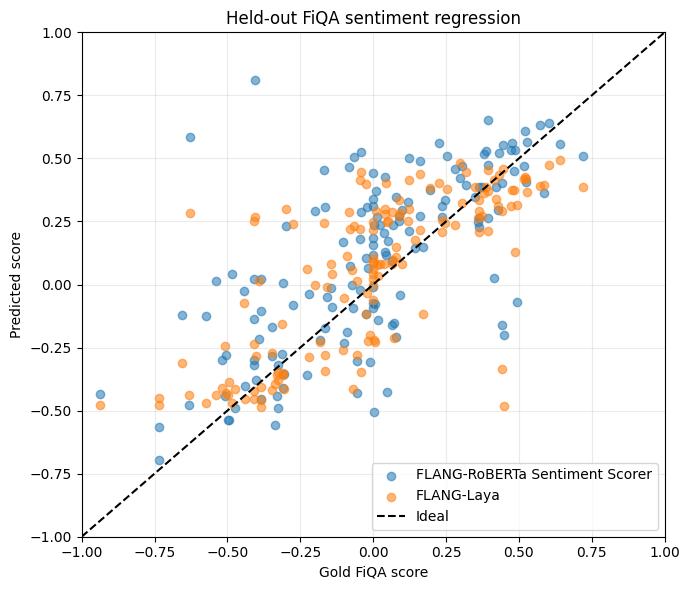

Saved metric CSV and plots in /kaggle/working/financial_model_export


In [10]:
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

metric_rows_export=[]
class_predictions={}

def evaluate_classifier_on_frame(model, tokenizer, frame, text_col, dataset_name, model_name):
    loader=DataLoader(FrameDataset(frame,tokenizer,text_col,"label"),batch_size=FLANG_BATCH,shuffle=False,collate_fn=batch_collator(tokenizer,False))
    model.eval(); gold=[]; pred=[]
    with torch.inference_mode():
        for batch in loader:
            gold.extend(batch["labels"].tolist())
            pred.extend(model(**move_inputs(batch)).argmax(-1).cpu().tolist())
    class_predictions[(dataset_name,model_name)]=(np.asarray(gold),np.asarray(pred))
    metric_rows_export.append({"task":"classification","dataset":dataset_name,"model":model_name,"n":len(gold),
        "accuracy":accuracy_score(gold,pred),"macro_precision":precision_score(gold,pred,average="macro",zero_division=0),
        "macro_recall":recall_score(gold,pred,average="macro",zero_division=0),"macro_f1":f1_score(gold,pred,average="macro",zero_division=0),
        "weighted_f1":f1_score(gold,pred,average="weighted",zero_division=0)})

# FLANG-RoBERTa, joint training, evaluated independently per corpus.
evaluate_classifier_on_frame(classification_model,classification_tok,phrase_test,"text","PhraseBank all-agreements","FLANG-RoBERTa Sentiment Classification")
evaluate_classifier_on_frame(classification_model,classification_tok,twitter_test,"text","Twitter Financial News","FLANG-RoBERTa Sentiment Classification")

# Laya final fine-tuned multitask checkpoint; same held-out examples and sentiment question.
import laya
laya_ft=laya.Agent(str(MODEL_DIR),device=DEVICE)
def laya_classify(frame, text_col, dataset_name):
    states=[str(x)[:2500] for x in frame[text_col].astype(str).tolist()]
    pred=[]
    for start in range(0,len(states),INFERENCE_BATCH_SIZE):
        result=laya_ft.predict_batch(states[start:start+INFERENCE_BATCH_SIZE],{"sentiment":class_question()},batch_size=INFERENCE_BATCH_SIZE,sort_by_length=True)
        pred.extend([LABEL_TO_ID_EXPORT[str(x["answers"]["sentiment"]["choice"]).lower()] for x in result])
    gold=frame.label.astype(int).to_numpy(); pred=np.asarray(pred)
    class_predictions[(dataset_name,"FLANG-Laya")]=(gold,pred)
    metric_rows_export.append({"task":"classification","dataset":dataset_name,"model":"FLANG-Laya","n":len(gold),
        "accuracy":accuracy_score(gold,pred),"macro_precision":precision_score(gold,pred,average="macro",zero_division=0),
        "macro_recall":recall_score(gold,pred,average="macro",zero_division=0),"macro_f1":f1_score(gold,pred,average="macro",zero_division=0),
        "weighted_f1":f1_score(gold,pred,average="weighted",zero_division=0)})
laya_classify(phrase_test,"text","PhraseBank all-agreements")
laya_classify(twitter_test,"text","Twitter Financial News")

# Regression scores for FLANG-RoBERTa and Laya on the FiQA held-out test split.
reg_loader=DataLoader(FrameDataset(fiqa_test,reg_tok,"sentence","sentiment_score"),batch_size=FLANG_BATCH,shuffle=False,collate_fn=batch_collator(reg_tok,True))
reg_model.eval(); fiqa_gold=[]; flang_pred=[]
with torch.inference_mode():
    for batch in reg_loader:
        fiqa_gold.extend(batch["labels"].tolist()); flang_pred.extend(reg_model(**move_inputs(batch)).squeeze(-1).float().cpu().tolist())
fiqa_gold=np.asarray(fiqa_gold); flang_pred=np.asarray(flang_pred)
regression_predictions={"FLANG-RoBERTa Sentiment Scorer":flang_pred}
metric_rows_export.append({"task":"regression","dataset":"FiQA","model":"FLANG-RoBERTa Sentiment Scorer","n":len(fiqa_gold),
    "mae":mean_absolute_error(fiqa_gold,flang_pred),"rmse":mean_squared_error(fiqa_gold,flang_pred)**.5,"r2":r2_score(fiqa_gold,flang_pred)})

def sentiment_score_from_answer(answer):
    # Convert Laya's 0..10 rubric score to the FiQA -1..1 sentiment range.
    return float(np.clip(float(answer["score"]), 0, 10) / 5.0 - 1.0)

laya_values=[]
for start in range(0,len(fiqa_test),INFERENCE_BATCH_SIZE):
    chunk=fiqa_test.iloc[start:start+INFERENCE_BATCH_SIZE]
    states=[state_for_fiqa(row) for _,row in chunk.iterrows()]
    ans=laya_ft.predict_batch(states,{"sentiment":regression_question()},batch_size=INFERENCE_BATCH_SIZE,sort_by_length=True)
    laya_values.extend([sentiment_score_from_answer(x["answers"]["sentiment"]) for x in ans])
laya_pred=np.asarray(laya_values); regression_predictions["FLANG-Laya"]=laya_pred
metric_rows_export.append({"task":"regression","dataset":"FiQA","model":"FLANG-Laya","n":len(fiqa_gold),
    "mae":mean_absolute_error(fiqa_gold,laya_pred),"rmse":mean_squared_error(fiqa_gold,laya_pred)**.5,"r2":r2_score(fiqa_gold,laya_pred)})

metrics_export=pd.DataFrame(metric_rows_export)
classification_metrics=metrics_export[metrics_export.task=="classification"].sort_values(["dataset","macro_f1"],ascending=[True,False])
regression_metrics_export=metrics_export[metrics_export.task=="regression"].sort_values("rmse")
print("HELD-OUT CLASSIFICATION METRICS")
display(classification_metrics.round(4))
print("HELD-OUT FiQA REGRESSION METRICS")
display(regression_metrics_export.round(4))
metrics_export.to_csv(EXPORT_DIR/"heldout_metrics.csv",index=False)

# Macro-F1 plot and per-model confusion matrices.
fig,ax=plt.subplots(figsize=(10,5))
for model_name in classification_metrics.model.unique():
    sub=classification_metrics[classification_metrics.model==model_name]
    ax.plot(sub.dataset,sub.macro_f1,marker="o",linewidth=2,label=model_name)
ax.set_ylim(0,1); ax.set_ylabel("Macro-F1"); ax.set_title("Held-out sentiment classification"); ax.grid(axis="y",alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(EXPORT_DIR/"classification_macro_f1.png",dpi=160); plt.show()

fig,axes=plt.subplots(2,2,figsize=(11,9))
for ax,((dataset,model_name),(gold,pred)) in zip(axes.flat,class_predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(gold,pred,labels=[0,1,2]),display_labels=LABELS_EXPORT).plot(ax=ax,colorbar=False,cmap="Blues",values_format="d")
    ax.set_title(f"{dataset} | {model_name}")
fig.tight_layout(); fig.savefig(EXPORT_DIR/"classification_confusion_matrices.png",dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(7,6))
for model_name,pred in regression_predictions.items(): ax.scatter(fiqa_gold,pred,alpha=.55,label=model_name)
ax.plot([-1,1],[-1,1],"k--",label="Ideal"); ax.set(xlabel="Gold FiQA score",ylabel="Predicted score",title="Held-out FiQA sentiment regression",xlim=(-1,1),ylim=(-1,1)); ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(EXPORT_DIR/"regression_predictions.png",dpi=160); plt.show()
print("Saved metric CSV and plots in",EXPORT_DIR)


## Export all weights for download

This cell copies the fine-tuned Laya checkpoint and packages it with the joint FLANG-RoBERTa classifier and FiQA regressor. The ZIP is the artifact to download from Kaggle’s notebook output panel.

In [11]:
import shutil
EXPORT_DIR=Path("/kaggle/working/financial_model_export")
if not (EXPORT_DIR/"FLANG_Laya"/"model.safetensors").exists():
    raise FileNotFoundError("Laya checkpoint is missing. Run the Laya fine-tuning cell successfully first.")
zip_path=Path(shutil.make_archive("/kaggle/working/financial_model_export","zip",root_dir=EXPORT_DIR))
print("Download this notebook output:",zip_path)
print("Contains:")
for p in sorted(EXPORT_DIR.rglob("*")):
    if p.is_file(): print(p.relative_to(EXPORT_DIR), f"({p.stat().st_size/1e6:.1f} MB)")


Download this notebook output: /kaggle/working/financial_model_export.zip
Contains:
FLANG_Laya/encoder/config.json (0.0 MB)
FLANG_Laya/model.safetensors (842.6 MB)
FLANG_Laya/rl_agent_config.json (0.0 MB)
FLANG_Laya/tokenizer/special_tokens_map.json (0.0 MB)
FLANG_Laya/tokenizer/tokenizer.json (3.6 MB)
FLANG_Laya/tokenizer/tokenizer_config.json (0.0 MB)
classification_confusion_matrices.png (0.1 MB)
classification_macro_f1.png (0.0 MB)
flang_roberta/FLANG_RoBERTa_Sentiment_Classification/encoder/config.json (0.0 MB)
flang_roberta/FLANG_RoBERTa_Sentiment_Classification/encoder/model.safetensors (539.6 MB)
flang_roberta/FLANG_RoBERTa_Sentiment_Classification/head.pt (0.8 MB)
flang_roberta/FLANG_RoBERTa_Sentiment_Classification/model_config.json (0.0 MB)
flang_roberta/FLANG_RoBERTa_Sentiment_Classification/tokenizer/added_tokens.json (0.0 MB)
flang_roberta/FLANG_RoBERTa_Sentiment_Classification/tokenizer/bpe.codes (1.1 MB)
flang_roberta/FLANG_RoBERTa_Sentiment_Classification/tokenizer/spe

## Upload the three models to Kaggle Models

Run this after training. Kaggle notebooks are authenticated through your Kaggle account. Each call uploads a separate PyTorch model variation under `arjunverma14142`. After upload, open each Kaggle model page and change **Settings → Visibility** to **Public** if Kaggle created it as private. Kaggle currently requires visibility to be set on the model page.

In [12]:
%pip -q install -U kagglehub
import kagglehub

MODEL_UPLOADS = [
    ("arjunverma14142/flang-roberta-sentiment-classification/pyTorch/default",
     EXPORT_DIR / "flang_roberta" / "FLANG_RoBERTa_Sentiment_Classification",
     "FLANG-RoBERTa Sentiment Classification; jointly fine-tuned on PhraseBank all-agreements and Twitter Financial News."),
    ("arjunverma14142/flang-roberta-sentiment-scorer/pyTorch/default",
     EXPORT_DIR / "flang_roberta" / "FLANG_RoBERTa_Sentiment_Scorer",
     "FLANG-RoBERTa Sentiment Scorer; fine-tuned on FiQA sentiment regression."),
    ("arjunverma14142/flang-laya/pyTorch/default",
     EXPORT_DIR / "FLANG_Laya",
     "FLANG-Laya; fine-tuned multitask financial sentiment and ticker relevance model."),
]
for handle, local_dir, notes in MODEL_UPLOADS:
    if not local_dir.is_dir():
        raise FileNotFoundError(f"Expected model folder does not exist: {local_dir}")
    print(f"Uploading {handle} from {local_dir}")
    kagglehub.model_upload(handle=handle, local_model_dir=str(local_dir), version_notes=notes)
print("Upload calls completed. Set each model's visibility to Public on its Kaggle model page.")


Note: you may need to restart the kernel to use updated packages.
Uploading arjunverma14142/flang-roberta-sentiment-classification/pyTorch/default from /kaggle/working/financial_model_export/flang_roberta/FLANG_RoBERTa_Sentiment_Classification
Uploading Model https://kaggle.com/models/arjunverma14142/flang-roberta-sentiment-classification/pyTorch/default ...
Model 'flang-roberta-sentiment-classification' does not exist or access is forbidden for user 'arjunverma14142'. Creating or handling Model...
Model 'flang-roberta-sentiment-classification' Created.
Starting upload for file /kaggle/working/financial_model_export/flang_roberta/FLANG_RoBERTa_Sentiment_Classification/model_config.json


Uploading: 100%|██████████| 327/327 [00:00<00:00, 705B/s]

Upload successful: /kaggle/working/financial_model_export/flang_roberta/FLANG_RoBERTa_Sentiment_Classification/model_config.json (327B)
Starting upload for file /kaggle/working/financial_model_export/flang_roberta/FLANG_RoBERTa_Sentiment_Classification/head.pt



Uploading: 100%|██████████| 795k/795k [00:01<00:00, 788kB/s]

Upload successful: /kaggle/working/financial_model_export/flang_roberta/FLANG_RoBERTa_Sentiment_Classification/head.pt (776KB)
Starting upload for file /kaggle/working/financial_model_export/flang_roberta/FLANG_RoBERTa_Sentiment_Classification/encoder/config.json


...


Uploading: 100%|██████████| 3.58M/3.58M [00:01<00:00, 2.90MB/s]

Upload successful: /kaggle/working/financial_model_export/FLANG_Laya/tokenizer/tokenizer.json (3MB)
Starting upload for file /kaggle/working/financial_model_export/FLANG_Laya/tokenizer/special_tokens_map.json



Uploading: 100%|██████████| 694/694 [00:00<00:00, 1.62kB/s]

Upload successful: /kaggle/working/financial_model_export/FLANG_Laya/tokenizer/special_tokens_map.json (694B)


Your model instance has been created.
Files are being processed...
See at: https://kaggle.com/models/arjunverma14142/flang-laya/pyTorch/default
Upload calls completed. Set each model's visibility to Public on its Kaggle model page.
